# 00bathymetry: the Bering Strait seabed

PF9, step 1. This notebook:

1. reads the IBCAO 5.2 grid (200 m, GeoTIFF) and cuts out the Bering Strait and Chukchi Sea window,
2. reprojects it to a local projection centred on the strait (no 180 degree meridian problem),
3. draws a first shaded relief map,
4. draws a depth profile across the strait (Cape Dezhnev to Cape Prince of Wales),
5. lowers the sea level step by step to find when the land bridge (Beringia) appears.

Input: `data/raw/` holds the IBCAO GeoTIFF downloaded by hand from gebco.net (IBCAO covers north of 64°N only).

Outputs: `data/bering_ibcao_laea_200m.tif` and pictures in `figures/`.

## Section 0. Settings

Lines marked `# <-` can be changed. `VISUAL:` settings only change pictures.

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw"
OUT_DIR = PROJECT_DIR / "data"
FIG_DIR = PROJECT_DIR / "figures"

RAW_FILE_NAME = ""  # <- leave empty to use the first IBCAO GeoTIFF found in data/raw

LAT_MIN = 64.0  # <- southern edge in degrees north (IBCAO starts at 64N)
LAT_MAX = 72.0  # <- northern edge
LON_WEST = 175.0  # <- western edge in degrees east (Chukotka side)
LON_EAST = -155.0  # <- eastern edge in degrees east, negative means west (Alaska side)

LOCAL_CRS = "+proj=laea +lat_0=67 +lon_0=-169 +datum=WGS84 +units=m +no_defs"  # <- local equal-area projection centred on the strait
OUT_RES_M = 200  # <- output cell size in metres

STRAIT_WEST = (66.08, -169.65)  # <- Cape Dezhnev, Russia (lat, lon)
STRAIT_EAST = (65.64, -168.09)  # <- Cape Prince of Wales, Alaska (lat, lon)

SEA_LEVEL_MAX_DROP = 130  # <- largest sea level fall tested, in metres
MAP_DROPS = [0, 40, 60, 120]  # <- VISUAL: sea level falls drawn in the land bridge figure
EXAGGERATION = 30  # <- VISUAL: vertical exaggeration of the hillshade
PLOT_MAX_PX = 1600  # <- VISUAL: largest picture side in pixels (the grid is thinned for drawing)

## Section 1. Libraries

In [2]:
import numpy as np
import pandas as pd
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin
from pyproj import Transformer
from scipy import ndimage
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

## Section 2. Find the IBCAO file

In [3]:
if RAW_FILE_NAME:
    raw_file = RAW_DIR / RAW_FILE_NAME
else:
    candidates = sorted(p for p in RAW_DIR.glob("*.tif*") if "ibcao" in p.name.lower())
    raw_file = candidates[0] if candidates else None

print("IBCAO file:", raw_file)
assert raw_file is not None and raw_file.exists(), "Put the IBCAO GeoTIFF in data/raw first"

with rasterio.open(raw_file) as src:
    print("CRS:", src.crs)
    print("Size:", src.width, "x", src.height)
    print("Cell size (m):", src.res)
    print("Nodata:", src.nodata)
    print("Data type:", src.dtypes[0])

IBCAO file: data\raw\ibcao_v5_2_2026_depth_200m.tiff
CRS: EPSG:3996
Size: 29100 x 29100
Cell size (m): (200.0, 200.0)
Nodata: None
Data type: float32


## Section 3. Cut out the Bering window

The window is a latitude and longitude box. Its edges are turned into IBCAO's polar stereographic metres, and only that rectangle is read from the big file.

In [4]:
lon_east_360 = LON_EAST % 360
edge_lons = np.linspace(LON_WEST, lon_east_360, 200)
edge_lats = np.linspace(LAT_MIN, LAT_MAX, 200)
ring_lons = np.concatenate([edge_lons, np.full(200, lon_east_360), edge_lons[::-1], np.full(200, LON_WEST)])
ring_lats = np.concatenate([np.full(200, LAT_MIN), edge_lats, np.full(200, LAT_MAX), edge_lats[::-1]])
ring_lons = ((ring_lons + 180) % 360) - 180

with rasterio.open(raw_file) as src:
    to_src = Transformer.from_crs("EPSG:4326", src.crs, always_xy=True)
    sx, sy = to_src.transform(ring_lons, ring_lats)
    window = from_bounds(sx.min(), sy.min(), sx.max(), sy.max(), src.transform)
    window = window.round_offsets().round_lengths()
    clip = src.read(1, window=window, masked=True).astype("float32")
    clip_transform = src.window_transform(window)
    src_crs = src.crs

clip_filled = clip.filled(np.nan)
print("Window read:", clip_filled.shape, "cells")
print("Missing cells:", round(float(np.isnan(clip_filled).mean()) * 100, 1), "%")

Window read: (5486, 7398) cells
Missing cells: 0.0 %


## Section 4. Reproject to the local projection

A Lambert azimuthal equal-area projection centred at 67°N, 169°W keeps the strait in the middle, north up, and every cell the same area. The 180° meridian runs through the window but causes no trouble in metres.

In [5]:
to_local = Transformer.from_crs("EPSG:4326", LOCAL_CRS, always_xy=True)
lx, ly = to_local.transform(ring_lons, ring_lats)
x0 = np.floor(lx.min() / OUT_RES_M) * OUT_RES_M
x1 = np.ceil(lx.max() / OUT_RES_M) * OUT_RES_M
y0 = np.floor(ly.min() / OUT_RES_M) * OUT_RES_M
y1 = np.ceil(ly.max() / OUT_RES_M) * OUT_RES_M
out_w = int((x1 - x0) / OUT_RES_M)
out_h = int((y1 - y0) / OUT_RES_M)
out_transform = from_origin(x0, y1, OUT_RES_M, OUT_RES_M)
elev = np.full((out_h, out_w), np.nan, dtype="float32")

reproject(source=clip_filled, destination=elev, src_transform=clip_transform, src_crs=src_crs, src_nodata=np.nan, dst_transform=out_transform, dst_crs=LOCAL_CRS, dst_nodata=np.nan, resampling=Resampling.bilinear)

print("Local grid:", out_w, "x", out_h, "cells of", OUT_RES_M, "m")
print("Extent:", round((x1 - x0) / 1000), "km wide,", round((y1 - y0) / 1000), "km tall")

out_file = OUT_DIR / f"bering_ibcao_laea_{OUT_RES_M}m.tif"
profile = {"driver": "GTiff", "height": out_h, "width": out_w, "count": 1, "dtype": "float32", "crs": LOCAL_CRS, "transform": out_transform, "nodata": np.nan, "compress": "deflate", "predictor": 3, "tiled": True}
with rasterio.open(out_file, "w", **profile) as dst:
    dst.write(elev, 1)
print("Saved:", out_file.name, round(out_file.stat().st_size / 1e6, 1), "MB")

Local grid: 7269 x 4818 cells of 200 m
Extent: 1454 km wide, 964 km tall
Saved: bering_ibcao_laea_200m.tif 85.3 MB


## Section 5. First look at the numbers

In [6]:
valid = ~np.isnan(elev)
sea = valid & (elev < 0)
land = valid & (elev >= 0)
cell_km2 = (OUT_RES_M / 1000) ** 2

names = ["deepest point (m)", "highest point (m)", "sea area (km2)", "land area (km2)", "median sea depth (m)", "sea shallower than 100 m (%)"]
values = [round(float(np.nanmin(elev))), round(float(np.nanmax(elev))), round(sea.sum() * cell_km2), round(land.sum() * cell_km2), round(float(np.median(elev[sea]))), round(float((sea & (elev > -100)).sum() / sea.sum() * 100), 1)]
summary = pd.DataFrame({"value": values}, index=names)
summary

,value
deepest point (m),-837.0
highest point (m),1977.0
sea area (km2),655899.0
land area (km2),649791.0
median sea depth (m),-45.0
sea shallower than 100 m (%),99.0


## Section 6. Shaded relief map

Sea in blues (stretched over the shallow shelf, where almost everything happens), land in greys and greens, lit from the northwest. The red line is the profile of Section 7.

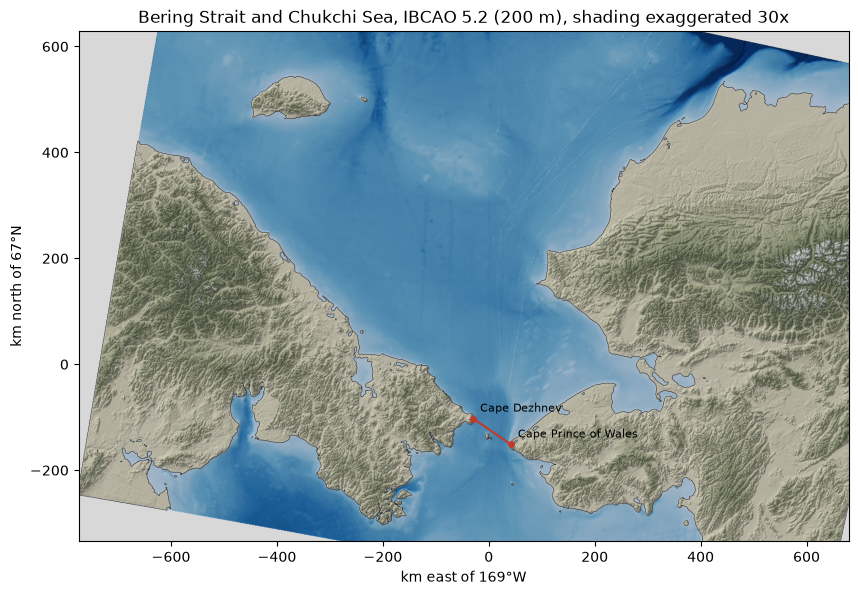

In [7]:
def hillshade(z, cell, exaggeration, azimuth=315, altitude=40):
    gy, gx = np.gradient(z * exaggeration, cell)
    slope = np.pi / 2 - np.arctan(np.hypot(gx, gy))
    aspect = np.arctan2(-gx, gy)
    az = np.radians(azimuth)
    alt = np.radians(altitude)
    shade = np.sin(alt) * np.sin(slope) + np.cos(alt) * np.cos(slope) * np.cos(az - aspect)
    return np.clip(shade, 0, 1)


step = max(1, int(np.ceil(max(out_w, out_h) / PLOT_MAX_PX)))
z = elev[::step, ::step]
z_fill = np.where(np.isnan(z), 0, z)
shade = hillshade(z_fill, OUT_RES_M * step, EXAGGERATION)

sea_cmap = LinearSegmentedColormap.from_list("sea", ["#08306b", "#2171b5", "#6baed6", "#c6dbef"])
land_cmap = LinearSegmentedColormap.from_list("land", ["#d9d4c0", "#a3a98a", "#6f7a5e", "#e8e8e8"])
sea_rgb = sea_cmap(np.clip((z_fill + 120) / 120, 0, 1))[..., :3]
land_rgb = land_cmap(np.clip(z_fill / 1500, 0, 1))[..., :3]
rgb = np.where((z_fill < 0)[..., None], sea_rgb, land_rgb)
rgb = rgb * (0.55 + 0.45 * shade[..., None])
rgb[np.isnan(z)] = 0.85

extent_km = [x0 / 1000, x1 / 1000, y0 / 1000, y1 / 1000]
pts = {"Cape Dezhnev": STRAIT_WEST, "Cape Prince of Wales": STRAIT_EAST}

fig, ax = plt.subplots(figsize=(10, 10 * out_h / out_w))
ax.imshow(rgb, extent=extent_km, origin="upper")
ax.contour(np.linspace(x0, x1, z.shape[1]) / 1000, np.linspace(y1, y0, z.shape[0]) / 1000, z_fill, levels=[0], colors="#333333", linewidths=0.4)
px, py = to_local.transform([STRAIT_WEST[1], STRAIT_EAST[1]], [STRAIT_WEST[0], STRAIT_EAST[0]])
ax.plot(np.array(px) / 1000, np.array(py) / 1000, color="#c0392b", linewidth=1.5)
for name, (la, lo) in pts.items():
    qx, qy = to_local.transform(lo, la)
    ax.plot(qx / 1000, qy / 1000, "o", color="#c0392b", markersize=4)
    ax.annotate(name, (qx / 1000, qy / 1000), xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.set_xlabel("km east of 169°W")
ax.set_ylabel("km north of 67°N")
ax.set_title(f"Bering Strait and Chukchi Sea, IBCAO 5.2 ({OUT_RES_M} m), shading exaggerated {EXAGGERATION}x")
fig.savefig(FIG_DIR / "00_map.png", dpi=150, bbox_inches="tight")
plt.show()

## Section 7. Across the strait

A straight line from Cape Dezhnev to Cape Prince of Wales, sampled every 200 m. The Diomede islands should show up in the middle.

Line length: 86.5 km
Water width along the line: 82.2 km
Deepest point on the line: -58 m
Mean depth of the water part: 47.9 m
Cross-section area: 3.94 km2
Rough mean speed if 1 Sv (1 million m3/s) flows through: 0.25 m/s


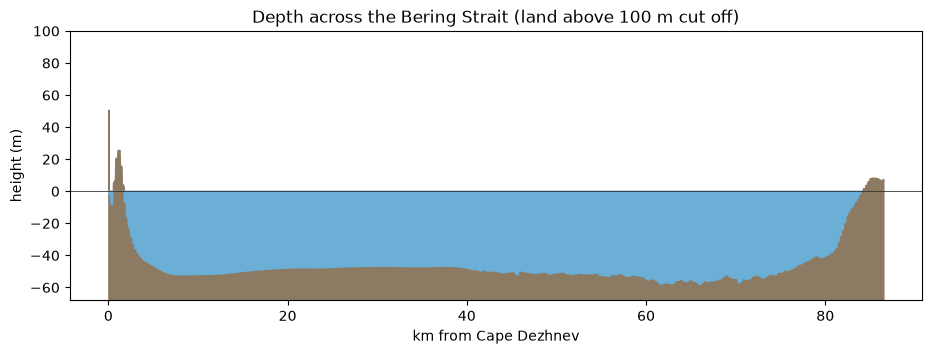

In [8]:
n_samples = 2000
line_lats = np.linspace(STRAIT_WEST[0], STRAIT_EAST[0], n_samples)
line_lons = np.linspace(STRAIT_WEST[1], STRAIT_EAST[1], n_samples)
lxs, lys = to_local.transform(line_lons, line_lats)
cols = ((np.array(lxs) - x0) / OUT_RES_M).astype(int)
rows = ((y1 - np.array(lys)) / OUT_RES_M).astype(int)
prof = elev[np.clip(rows, 0, out_h - 1), np.clip(cols, 0, out_w - 1)]
dist_km = np.hypot(np.array(lxs) - lxs[0], np.array(lys) - lys[0]) / 1000
dx_m = (dist_km[1] - dist_km[0]) * 1000

wet = prof < 0
strait_width_km = wet.sum() * dx_m / 1000
cross_area_km2 = float(-prof[wet].sum() * dx_m / 1e6)
print("Line length:", round(dist_km[-1], 1), "km")
print("Water width along the line:", round(strait_width_km, 1), "km")
print("Deepest point on the line:", round(float(np.nanmin(prof))), "m")
print("Mean depth of the water part:", round(float(-prof[wet].mean()), 1), "m")
print("Cross-section area:", round(cross_area_km2, 2), "km2")
print("Rough mean speed if 1 Sv (1 million m3/s) flows through:", round(1e6 / (cross_area_km2 * 1e6), 2), "m/s")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.fill_between(dist_km, prof, np.nanmin(prof) - 10, color="#8c7b62")
ax.fill_between(dist_km, prof, 0, where=wet, color="#6baed6")
ax.axhline(0, color="#333333", linewidth=0.6)
ax.set_xlabel("km from Cape Dezhnev")
ax.set_ylabel("height (m)")
ax.set_ylim(np.nanmin(prof) - 10, 100)
ax.set_title("Depth across the Bering Strait (land above 100 m cut off)")
fig.savefig(FIG_DIR / "00_strait_profile.png", dpi=150, bbox_inches="tight")
plt.show()

## Section 8. Lowering the sea: when does the land bridge appear?

For each sea level fall (0 to `SEA_LEVEL_MAX_DROP` m, 1 m steps), water is everything deeper than the fall. The check: is any body of water still touching both the southern edge of the window (Bering Sea) and the northern edge (Arctic)? The first fall at which none does is when Asia and America join inside the window. That fall is added as an extra panel to the land bridge figure, so we can see where the last link broke.

Caveats: today's seabed is not exactly the ice-age land surface (sediment, land rising and sinking under ice), and the window stops at 64°N, so this tests the strait only, not the whole of Beringia. Water cells count as joined only through their sides, not corners.

In [9]:
elev0 = np.where(np.isnan(elev), np.inf, elev)
rows_out = []
sill_drop = None
for drop in range(0, SEA_LEVEL_MAX_DROP + 1):
    water = elev0 < -drop
    labels, _ = ndimage.label(water)
    south_labels = set(np.unique(labels[-1, :])) - {0}
    north_labels = set(np.unique(labels[0, :])) - {0}
    joined = len(south_labels & north_labels) > 0
    if not joined and sill_drop is None:
        sill_drop = drop
    rows_out.append({"sea level fall (m)": drop, "land area (km2)": round(float(((elev0 >= -drop) & valid).sum() * cell_km2)), "seas still joined": joined})

bridge = pd.DataFrame(rows_out)
print("Asia and America join (no sea route south to north) at a sea level fall of:", sill_drop, "m")
bridge[bridge["sea level fall (m)"] % 10 == 0]

Asia and America join (no sea route south to north) at a sea level fall of: 45 m


,sea level fall (m),land area (km2),seas still joined
0,0,649791,True
10,10,676891,True
20,20,726096,True
30,30,786035,True
40,40,893715,True
50,50,1106601,False
60,60,1251300,False
70,70,1273890,False
80,80,1288992,False
90,90,1297504,False


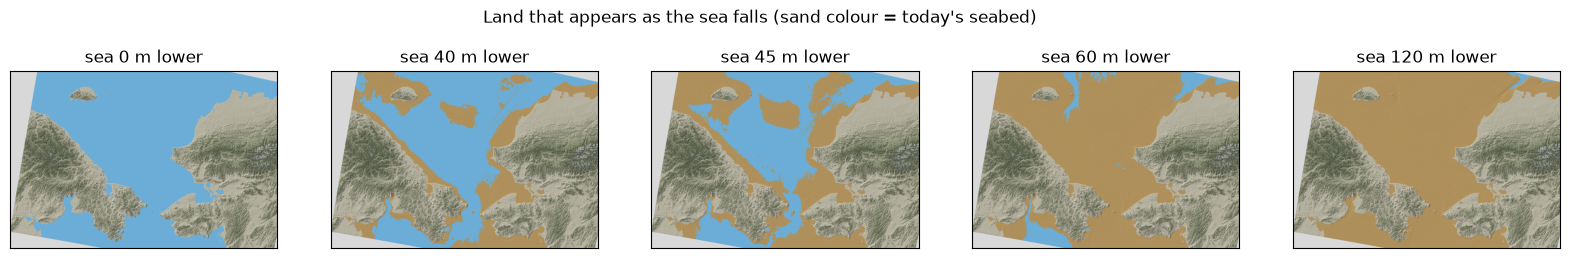

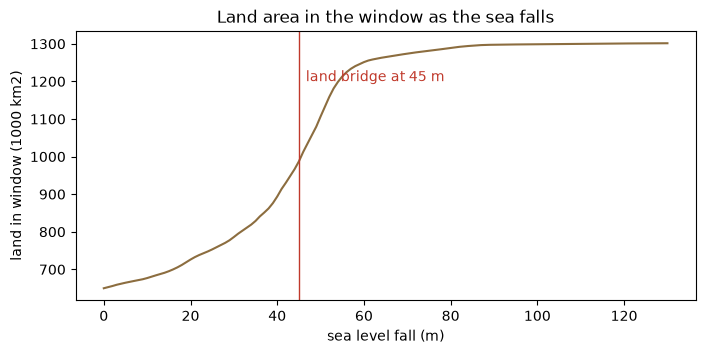

In [10]:
panel_drops = sorted(set(MAP_DROPS + ([sill_drop] if sill_drop is not None else [])))
fig, axes = plt.subplots(1, len(panel_drops), figsize=(4 * len(panel_drops), 4 * out_h / out_w))
for ax, drop in zip(axes, panel_drops):
    is_land = z_fill >= -drop
    pic = np.where(is_land[..., None], land_rgb * (0.55 + 0.45 * shade[..., None]), np.array([0.42, 0.68, 0.84]))
    pic = np.where((is_land & (z_fill < 0))[..., None], np.array([0.80, 0.66, 0.42]) * (0.6 + 0.4 * shade[..., None]), pic)
    pic[np.isnan(z)] = 0.85
    ax.imshow(pic, extent=extent_km, origin="upper")
    ax.set_title(f"sea {drop} m lower")
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Land that appears as the sea falls (sand colour = today's seabed)", y=1.06)
fig.savefig(FIG_DIR / "00_land_bridge.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(bridge["sea level fall (m)"], bridge["land area (km2)"] / 1000, color="#8c6d3f")
if sill_drop is not None:
    ax.axvline(sill_drop, color="#c0392b", linewidth=1)
    ax.annotate(f"land bridge at {sill_drop} m", (sill_drop, ax.get_ylim()[1] * 0.9), xytext=(5, 0), textcoords="offset points", color="#c0392b")
ax.set_xlabel("sea level fall (m)")
ax.set_ylabel("land in window (1000 km2)")
ax.set_title("Land area in the window as the sea falls")
fig.savefig(FIG_DIR / "00_land_area.png", dpi=150, bbox_inches="tight")
plt.show()

___
**END**